# Bài 20: Đánh giá Toàn diện Mô hình, Thiết kế Thí nghiệm Khoa học và Tinh chỉnh Siêu tham số (Hyperparameter Tuning)

## 1. Mục tiêu học tập
- Làm chủ hệ thống độ đo đánh giá (`Evaluation Metrics`) toàn diện vượt xa chỉ số `Accuracy` đơn lẻ:
  - Phân loại: `Accuracy`, `Precision`, `Recall`, `Specificity`, `F1-score` (`Macro`, `Micro`, `Weighted`), `Support`, `Confusion Matrix`, `ROC-AUC`, `PR-AUC`.
  - Chọn ngưỡng quyết định tối ưu (`Optimal Threshold Tuning`) theo yêu cầu bài toán thực tế.
  - Đánh giá độ đáng tin cậy của xác suất dự đoán: **Độ hiệu chỉnh xác suất (`Calibration` & `Expected Calibration Error - ECE`)**.
- Biết cách thiết kế một **Thí nghiệm Khoa học (`Scientific Experiment Design`)** và lập bảng **Nghiên cứu Cắt bỏ Thành phần (`Ablation Study`)** — mỗi lần chỉ thay đổi đúng 1 yếu tố trên cùng `seed` và cùng cách chia tập.
- Thực hành tìm kiếm siêu tham số (`Grid Search` / `Random Search`) chỉ trên tập `Train/Validation`, giữ tập `Test` hoàn toàn độc lập.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 05, 06 và 11.

## 3. Thời gian học dự kiến
- Khoảng **2.0 giờ** (ước tính).

## 4, 5, 6 & 7. Giải thích Trực quan, Từ điển Keyword & Công thức Toán học
1. **Khi nào dùng `Macro-F1`, `Micro-F1`, `Weighted-F1`, `ROC-AUC` hay `PR-AUC`?**
   - Dữ liệu cân bằng, mọi lỗi ngang nhau $\longrightarrow$ `Accuracy` + `Macro-F1`.
   - Dữ liệu lệch lớp, cần bảo vệ lớp thiểu số quan trọng ngang lớp đa số $\longrightarrow$ **`Macro-F1`** + **`PR-AUC`**.
   - Chi phí bỏ sót lỗi cực kỳ nguy hiểm (y tế, an toàn) $\longrightarrow$ Ưu tiên **`Recall`** cao (hạ thấp `threshold`), kiểm soát `Specificity` / `Precision` ở mức chấp nhận được.
2. **Sai số Hiệu chỉnh Kỳ vọng (`Expected Calibration Error - ECE`)**:
   Chia đoạn xác suất $[0, 1]$ thành $M$ ngăn (`bins`) $B_m$. Trong mỗi ngăn, so sánh độ chính xác thực tế $\text{acc}(B_m)$ với độ tự tin trung bình $\text{conf}(B_m)$:
   $$\text{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{N} \Big|\text{acc}(B_m) - \text{conf}(B_m)\Big|$$
   Một mô hình hiệu chỉnh tốt có $\text{ECE} \approx 0$ (nói tự tin `80%` thì đúng thực tế khoảng `80%`).


In [1]:
# Cell 1: Tính Bộ Độ đo Toàn diện (Accuracy, Precision, Recall, Specificity, Macro/Weighted F1, ROC-AUC, PR-AUC)
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, average_precision_score

from src.utils import set_seed
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.features import extract_combined_features
from src.evaluation import compute_classification_metrics

set_seed(42)

ds = generate_synthetic_shapes_dataset(num_samples=320, image_size=32, seed=42, noise_std=14.0)
X_feats = extract_combined_features(ds["images"])
y_all = ds["labels"]
class_names = ds["class_names"]

idx_all = np.arange(len(y_all))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.40, random_state=42, stratify=y_all)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=y_all[idx_temp])

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_feats[idx_tr])
X_va = scaler.transform(X_feats[idx_va])
X_te = scaler.transform(X_feats[idx_te])
y_tr, y_va, y_te = y_all[idx_tr], y_all[idx_va], y_all[idx_te]

clf = SVC(C=1.0, kernel="rbf", probability=True, random_state=42).fit(X_tr, y_tr)
va_probs = clf.predict_proba(X_va)
va_preds = va_probs.argmax(axis=1)

metrics_report = compute_classification_metrics(y_va, va_preds, class_names)
per_cls_df = pd.DataFrame(metrics_report["per_class"]).T.round(4)
print("=== BẢNG CHI TIẾT PRECISION, RECALL, SPECIFICITY, F1 & SUPPORT TỪNG LỚP ===")
print(per_cls_df.to_string())
print(f"\nTổng hợp -> Accuracy: {metrics_report['accuracy']:.4f} | Macro-F1: {metrics_report['macro_f1']:.4f} | Weighted-F1: {metrics_report['weighted_f1']:.4f}")


=== BẢNG CHI TIẾT PRECISION, RECALL, SPECIFICITY, F1 & SUPPORT TỪNG LỚP ===
          precision  recall  specificity      f1  support
circle       0.7619  1.0000       0.8958  0.8649     16.0
square       0.9286  0.8125       0.9792  0.8667     16.0
triangle     1.0000  0.8750       1.0000  0.9333     16.0
cross        0.9333  0.8750       0.9792  0.9032     16.0

Tổng hợp -> Accuracy: 0.8906 | Macro-F1: 0.8920 | Weighted-F1: 0.8920


In [2]:
# Cell 2: Tinh chỉnh Ngưỡng Quyết định (Threshold Tuning) và Đo Độ Hiệu chỉnh Xác suất (Calibration / ECE)
def compute_ece(y_true: np.ndarray, y_prob_matrix: np.ndarray, n_bins: int = 5) -> float:
    confidences = y_prob_matrix.max(axis=1)
    predictions = y_prob_matrix.argmax(axis=1)
    accuracies = (predictions == y_true).astype(np.float64)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b_i in range(n_bins):
        in_bin = (confidences > bin_boundaries[b_i]) & (confidences <= bin_boundaries[b_i + 1])
        prop_in_bin = float(in_bin.mean())
        if prop_in_bin > 0:
            acc_in_bin = float(accuracies[in_bin].mean())
            conf_in_bin = float(confidences[in_bin].mean())
            ece += abs(acc_in_bin - conf_in_bin) * prop_in_bin
    return float(ece)


ece_val = compute_ece(y_va, va_probs, n_bins=5)
print(f"Sai số hiệu chỉnh xác suất kỳ vọng (Expected Calibration Error - ECE): {ece_val:.4f}")

# Tinh chỉnh ngưỡng (Threshold Tuning) cho bài toán nhị phân: Lớp 'cross' (class 3) vs Các lớp còn lại
y_va_bin = (y_va == 3).astype(np.int64)
prob_cross = va_probs[:, 3]
print(f"Lớp 'cross' (One-vs-Rest) -> ROC-AUC: {roc_auc_score(y_va_bin, prob_cross):.4f} | PR-AUC: {average_precision_score(y_va_bin, prob_cross):.4f}")

for th in [0.20, 0.50, 0.80]:
    pred_bin = (prob_cross >= th).astype(np.int64)
    tp = int(((pred_bin == 1) & (y_va_bin == 1)).sum())
    fp = int(((pred_bin == 1) & (y_va_bin == 0)).sum())
    fn = int(((pred_bin == 0) & (y_va_bin == 1)).sum())
    prec = tp / max(1, tp + fp)
    rec = tp / max(1, tp + fn)
    print(f"  Ngưỡng τ = {th:.2f} -> Precision = {prec*100:5.1f}% | Recall = {rec*100:5.1f}%")


Sai số hiệu chỉnh xác suất kỳ vọng (Expected Calibration Error - ECE): 0.1091
Lớp 'cross' (One-vs-Rest) -> ROC-AUC: 0.9831 | PR-AUC: 0.9465
  Ngưỡng τ = 0.20 -> Precision =  76.2% | Recall = 100.0%
  Ngưỡng τ = 0.50 -> Precision =  93.3% | Recall =  87.5%
  Ngưỡng τ = 0.80 -> Precision =  90.0% | Recall =  56.2%


=== BẢNG ABLATION STUDY (CHỨNG MINH ĐÓNG GÓP CỦA TỪNG THÀNH PHẦN) ===
                                          Experiment  Val_Acc  Val_Macro_F1
A0: Baseline (Chỉ dùng Color Histogram + Linear SVM)   0.5156        0.5193
     A1: Thay bằng đặc trưng HOG (144d) + Linear SVM   0.7812        0.7780
           A2: HOG + Color + LBP (184d) + Linear SVM   0.8750        0.8727
       A3: HOG + Color + LBP (184d) + RBF Kernel SVM   0.8906        0.8909

[Grid Search] Cấu hình tốt nhất chọn từ Validation: {'C': 5.0, 'gamma': 0.005} (Val Macro-F1 = 0.9215)
[Final Test Report] Test Accuracy = 90.6% | Test Macro-F1 = 0.9057


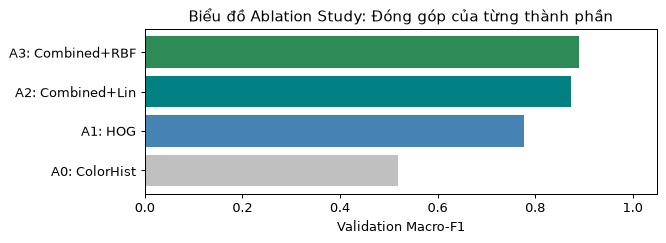

In [3]:
# Cell 3: Thiết kế Bảng Thí nghiệm Cắt bỏ Thành phần (Ablation Study) & Tìm kiếm Siêu tham số Không Rò rỉ Tập Test
# 1. Ablation Study: Đánh giá đóng góp thực sự của từng thành phần trong pipeline
ablation_configs = [
    ("A0: Baseline (Chỉ dùng Color Histogram + Linear SVM)", X_feats[:, 144:168], "linear", 1.0),
    ("A1: Thay bằng đặc trưng HOG (144d) + Linear SVM", X_feats[:, :144], "linear", 1.0),
    ("A2: HOG + Color + LBP (184d) + Linear SVM", X_feats, "linear", 1.0),
    ("A3: HOG + Color + LBP (184d) + RBF Kernel SVM", X_feats, "rbf", 1.0),
]

ablation_rows = []
for exp_name, F_sub, kern, c_val in ablation_configs:
    sc_sub = StandardScaler()
    X_tr_s = sc_sub.fit_transform(F_sub[idx_tr])
    X_va_s = sc_sub.transform(F_sub[idx_va])
    m_sub = SVC(C=c_val, kernel=kern, random_state=42).fit(X_tr_s, y_tr)
    res_sub = compute_classification_metrics(y_va, m_sub.predict(X_va_s), class_names)
    ablation_rows.append({"Experiment": exp_name, "Val_Acc": round(res_sub["accuracy"], 4), "Val_Macro_F1": round(res_sub["macro_f1"], 4)})

print("=== BẢNG ABLATION STUDY (CHỨNG MINH ĐÓNG GÓP CỦA TỪNG THÀNH PHẦN) ===")
print(pd.DataFrame(ablation_rows).to_string(index=False))

# 2. Grid Search chọn siêu tham số (C, gamma) CHỈ TRÊN TẬP VALIDATION, sau đó đánh giá đúng 1 lần trên tập TEST
best_cfg = None
best_val_f1 = -1.0
best_model = None

for c_cand in [0.1, 1.0, 5.0, 10.0]:
    for gamma_cand in ["scale", 0.005, 0.02]:
        cand_clf = SVC(C=c_cand, gamma=gamma_cand, kernel="rbf", random_state=42).fit(X_tr, y_tr)
        val_f1 = compute_classification_metrics(y_va, cand_clf.predict(X_va), class_names)["macro_f1"]
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_cfg = {"C": c_cand, "gamma": gamma_cand}
            best_model = cand_clf

# Đánh giá lần cuối cùng trên tập Test bị khóa kín
final_test_metrics = compute_classification_metrics(y_te, best_model.predict(X_te), class_names)
print(f"\n[Grid Search] Cấu hình tốt nhất chọn từ Validation: {best_cfg} (Val Macro-F1 = {best_val_f1:.4f})")
print(f"[Final Test Report] Test Accuracy = {final_test_metrics['accuracy']*100:.1f}% | Test Macro-F1 = {final_test_metrics['macro_f1']:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
exp_labels = ["A0: ColorHist", "A1: HOG", "A2: Combined+Lin", "A3: Combined+RBF"]
exp_f1s = [r["Val_Macro_F1"] for r in ablation_rows]
ax.barh(exp_labels, exp_f1s, color=["silver", "steelblue", "teal", "seagreen"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Validation Macro-F1")
ax.set_title("Biểu đồ Ablation Study: Đóng góp của từng thành phần")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 2**: Khi giảm ngưỡng quyết định $\tau$ từ `0.80` xuống `0.20`, độ nhạy (`Recall`) tăng mạnh nhưng độ chuẩn xác (`Precision`) giảm. Nhờ vậy, bạn có thể điều chỉnh $\tau$ trên tập `Validation` để đáp ứng yêu cầu nghiệp vụ mà không cần huấn luyện lại mô hình!
- **Ở Cell 3**: Bảng `Ablation Study` chỉ ra chính xác bước nhảy chất lượng lớn nhất đến từ việc đưa đặc trưng hình dáng **`HOG`** vào (`A0 -> A1`) và bước tinh chỉnh cuối đến từ nhân phi tuyến **`RBF`** (`A2 -> A3`).

## 14. Bài tập tự làm
- **Cơ bản**: Viết hàm tìm ngưỡng $\tau^* \in [0.05, 0.95]$ tối đa hóa điểm `F1-score` của lớp `cross` trên tập `Validation`, sau đó áp dụng ngưỡng $\tau^*$ đó lên tập `Test`.
- **Trung cấp**: Thực hiện kỹ thuật **Temperature Scaling** ($p_i = \text{softmax}(z_i / T)$) trên tập Validation để làm mịn xác suất và giảm chỉ số `ECE`.
- **Nâng cao**: Thiết kế vòng lặp **Random Search** lấy mẫu `learning_rate` theo thang đo logarit (`10 ** np.random.uniform(-4, -1)`), giải thích vì sao `learning_rate` phải lấy mẫu trên thang log thay vì thang tuyến tính đều!

## 15. Gợi ý và Lời giải


In [4]:
# Cell 4: Lời giải hoàn chỉnh cho bài tập Bài 20
# 1. Cơ bản: Tìm ngưỡng tối ưu F1 trên Validation và áp dụng sang Test
best_tau, best_f1_cross = 0.5, 0.0
for tau in np.linspace(0.1, 0.9, 17):
    p_b = (prob_cross >= tau).astype(np.int64)
    tp = ((p_b == 1) & (y_va_bin == 1)).sum()
    fp = ((p_b == 1) & (y_va_bin == 0)).sum()
    fn = ((p_b == 0) & (y_va_bin == 1)).sum()
    f1_c = (2 * tp) / max(1, 2 * tp + fp + fn)
    if f1_c > best_f1_cross:
        best_f1_cross, best_tau = float(f1_c), float(tau)
print(f"[Cơ bản] Ngưỡng tối ưu trên Val: τ* = {best_tau:.2f} (Val F1 = {best_f1_cross:.4f})")

# 2. Trung cấp: Temperature Scaling giảm hiện tượng tự tin thái quá (Overconfidence)
raw_logits = np.log(np.clip(va_probs, 1e-8, 1.0))
for temp in [0.5, 1.0, 1.5]:
    scaled_exp = np.exp(raw_logits / temp)
    scaled_probs = scaled_exp / scaled_exp.sum(axis=1, keepdims=True)
    print(f"[Trung cấp] Temperature T={temp:.1f} -> ECE = {compute_ece(y_va, scaled_probs):.4f}")

# 3. Nâng cao: Lấy mẫu Learning Rate theo thang Log-Uniform (đảm bảo mỗi bậc độ lớn 1e-4..1e-3, 1e-3..1e-2 có xác suất ngang nhau)
rng = np.random.default_rng(42)
log_sampled_lrs = 10.0 ** rng.uniform(-4.0, -1.0, size=6)
print("[Nâng cao] 6 giá trị LR lấy mẫu Log-Uniform:", [f"{v:.2e}" for v in np.sort(log_sampled_lrs)])


[Cơ bản] Ngưỡng tối ưu trên Val: τ* = 0.35 (Val F1 = 0.9032)
[Trung cấp] Temperature T=0.5 -> ECE = 0.0325
[Trung cấp] Temperature T=1.0 -> ECE = 0.1091
[Trung cấp] Temperature T=1.5 -> ECE = 0.1859
[Nâng cao] 6 giá trị LR lấy mẫu Log-Uniform: ['1.92e-04', '2.07e-03', '1.24e-02', '2.10e-02', '3.77e-02', '8.45e-02']


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Thành thạo bộ metric đa chiều, `Threshold Tuning`, `Calibration (ECE)`, `Ablation Study` và `Hyperparameter Tuning` chuẩn khoa học.
- [x] Sẵn sàng chuyển sang **Bài 21: `21_inference_export_and_optimization.ipynb`** để đóng gói mô hình đưa vào chương trình xử lý ảnh thực tế!

## 17. Nguồn tham khảo
- Guo, C. et al. (2017), *On Calibration of Modern Neural Networks*, ICML.
- Bergstra, J., & Bengio, Y. (2012), *Random Search for Hyper-Parameter Optimization*, JMLR.
